Predicting Maize harvest under climate change 

mission 
problem 

use case: This model predicts maize yield (tonnes per hectare) for a farm field from rainfall, temperature, dryness, fertilizer and farming practices 

who use it : 
what for : 

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
import os 
RANDOM_STATE = 42
# relative path to the data file
DATA_PATH = "One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv"
for folder in [".", "..", "../.."]:
    if os.path.exists(os.path.join(folder, DATA_PATH)):
        DATA_PATH = os.path.join(folder, DATA_PATH)
        break
print("dataset found at:", DATA_PATH)

dataset found at: ../..\One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv


1. Load the data 

each row is one farm field in one season , the target is yield_kg_ha , which is kilogram of maize harvested per hectare 

In [3]:
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 60)

In [4]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]}, Columns: {df_raw.shape[1]}")
df_raw.head()


Rows: 14773, Columns: 53


,year,country,iso,season,cz,lon,lat,strat,avg_season_gdd,avg_season_ai,avg_season_tavg,season_prec,season_prec_1,season_prec_2,season_prec_3,elev,twi,soil_rzpawhc,soil_clay,soil_pH,soil_orgC,soil_ECEC,plant_date,harvest_date,plant_date_dev,plant_doy,pl_m2,row_spacing,hybrid,hyb_type,hyb_mat,hyb_yor,hyb_tol_mln,hyb_tol_msv,hyb_tol_gls,hyb_tol_nclb,hyb_tol_rust,hyb_tol_ear_rot,N_kg_ha,P_kg_ha,K_kg_ha,compost,comp_kg_ha,manure,fert_in_hole,lime_kg_ha,weeding,pesticide,disease,pest,striga,water_excess,yield_kg_ha
0,2016,kenya,KEN,first season,7701,34.067,0.227,01_KEN7701S1,2509.099854,0.998492,21.275661,677.039708,228.759519,365.227443,83.052746,1280,8.322142,120.0,34.0,6.3,11.182494,13.879732,2016-04-13,NaN,22.0,104.0,NaN,70.666656,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,NaN,NaN,False,False,NaN,False,1462.951369
1,2017,kenya,KEN,first season,7701,34.100,0.238,01_KEN7701S1,2552.900146,1.038017,21.507408,760.532583,154.624451,464.134379,141.773752,1288,10.117007,120.0,38.0,5.9,12.463738,12.463738,2017-03-31,2017-07-14,8.0,90.0,2.736283,68.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,False,True,False,True,NaN,False,2817.771269
2,2019,kenya,KEN,first season,7701,34.082,0.247,01_KEN7701S1,2580.099854,1.008526,21.651323,724.153837,181.676820,359.354439,183.122578,1243,7.909871,120.0,33.0,6.2,10.023176,10.023176,2019-04-15,2019-08-05,23.0,105.0,4.541739,72.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,27.873444,13.83788,0.0,False,0.0,NaN,True,0.0,False,False,False,True,NaN,False,0.000000
3,2020,kenya,KEN,first season,7701,34.098,0.232,01_KEN7701S1,2562.800049,1.018445,21.559790,998.342599,379.451999,428.776234,190.114366,1271,8.969049,120.0,32.0,6.0,10.023176,10.023176,2020-03-28,2020-07-16,6.0,88.0,3.986111,NaN,True,3_way_hyb,1.0,2003.0,False,False,True,False,False,True,44.478900,49.42100,0.0,True,NaN,True,False,0.0,True,False,False,True,True,False,4788.722787
4,2020,kenya,KEN,first season,7701,34.094,0.272,01_KEN7701S1,2612.800049,1.023641,21.824339,998.342599,379.451999,428.776234,190.114366,1226,6.008638,120.0,33.0,5.9,12.463738,11.182494,2020-02-05,2020-08-04,-46.0,36.0,2.277778,NaN,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,NaN,NaN,False,0.0,False,NaN,False,False,True,False,2193.982268


In [5]:
df_raw["country"].value_counts()

country
kenya       7258
tanzania    3710
rwanda      2080
zambia       861
burundi      640
nigeria      115
uganda       109
Name: count, dtype: int64

In [6]:
missing = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0]

manure             94.0
striga             82.9
hyb_type           82.5
hyb_yor            53.5
comp_kg_ha         52.3
hyb_tol_rust       48.7
hyb_tol_msv        48.7
hyb_tol_gls        48.7
hyb_tol_ear_rot    48.7
hyb_tol_mln        48.7
hyb_tol_nclb       48.7
hyb_mat            47.9
row_spacing        42.9
compost            39.3
pesticide          38.5
pl_m2              31.2
harvest_date       30.4
soil_orgC          30.1
soil_pH            30.1
soil_clay          30.1
soil_rzpawhc       30.1
soil_ECEC          30.1
weeding            25.8
K_kg_ha            24.9
plant_doy          24.3
plant_date         24.3
plant_date_dev     24.3
strat              17.1
lime_kg_ha          9.0
hybrid              8.3
avg_season_ai       0.3
avg_season_gdd      0.3
avg_season_tavg     0.3
dtype: float64

Converting the  yield to tonnes 

1 tonne is equal to 1000 kg so tonnes per hectare give small numbers that are easy to read and get also a readable error or MSE

In [7]:
df_raw["yield_t_ha"] = df_raw["yield_kg_ha"] / 1000
df_raw["yield_t_ha"].describe().round(2)

count    14773.00
mean         2.97
std          1.69
min          0.00
25%          1.74
50%          2.71
75%          3.95
max         11.14
Name: yield_t_ha, dtype: float64

2. Exploring the data using visualizations 

Plot 1 - Correlation heatmap 

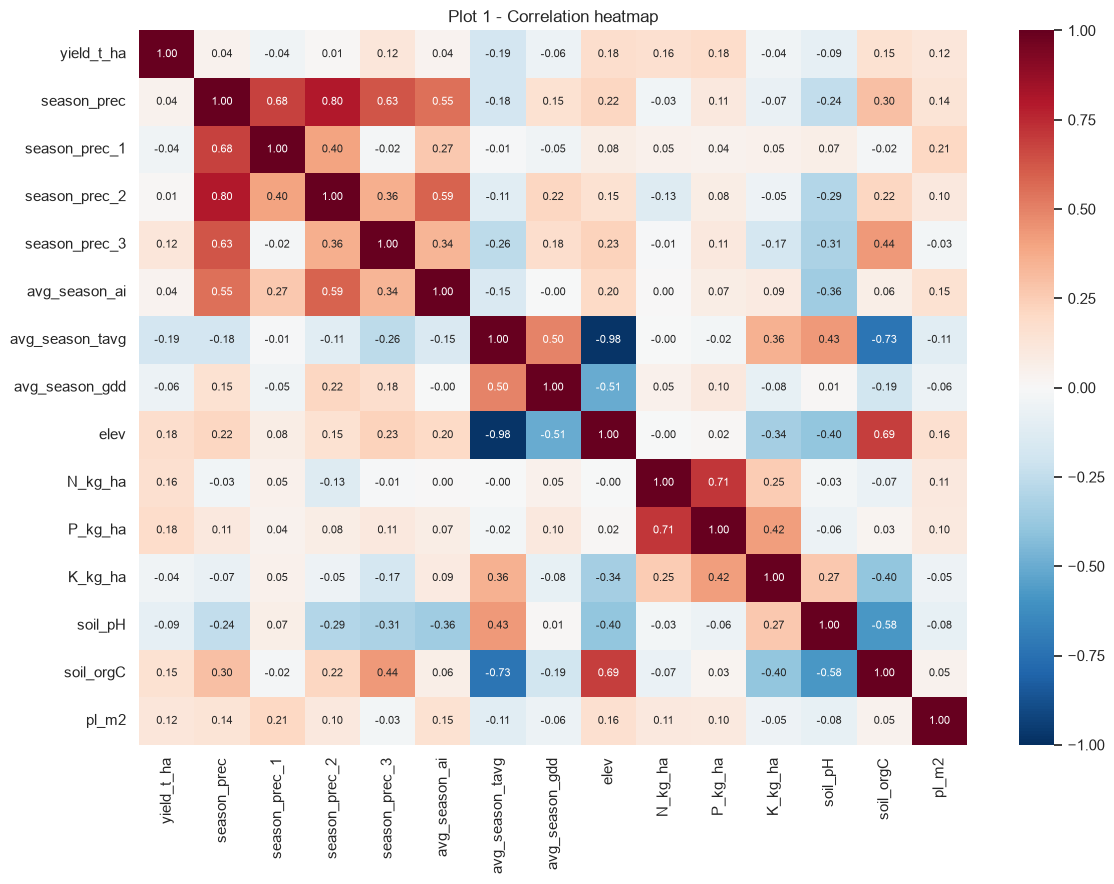

In [8]:
heatmap_cols = ["yield_t_ha", "season_prec", "season_prec_1", "season_prec_2",
                "season_prec_3", "avg_season_ai", "avg_season_tavg", "avg_season_gdd",
                "elev", "N_kg_ha", "P_kg_ha", "K_kg_ha", "soil_pH", "soil_orgC", "pl_m2"]

corr = df_raw[heatmap_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 8})
plt.title("Plot 1 - Correlation heatmap")
plt.tight_layout()
plt.show()

what the plot shows : this plot shows that no column is strongly related to yield by itself 

what i decided : i keep temperature and drop elevation because they carry the same informatino so i keep total season rainfall and drop its three parts and i also kep both nitrogen and phosphorus because they are two different fertilizers . moreover, since there is no feature that has a strong straight-line link with yield , i am expecting the linear models to have a bit of struggle.

Plot 2 : histogram 

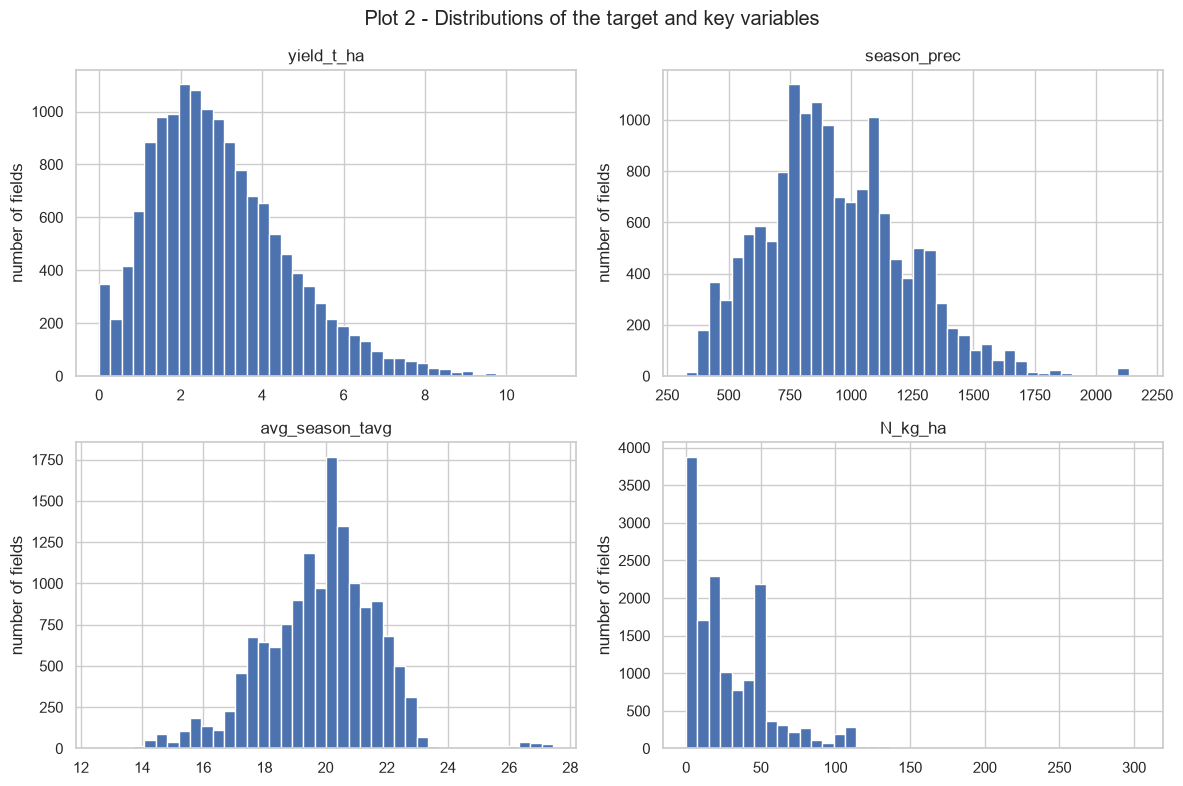

In [9]:
hist_cols = ["yield_t_ha", "season_prec", "avg_season_tavg", "N_kg_ha"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    ax.hist(df_raw[col].dropna(), bins=40)
    ax.set_title(col)
    ax.set_ylabel("number of fields")
fig.suptitle("Plot 2 - Distributions of the target and key variables")
plt.tight_layout()
plt.show()

In [10]:
print("Fields with zero harvest:", (df_raw["yield_t_ha"] == 0).sum())
print("Fields with more than 800 mm of rain:", (df_raw["season_prec"] > 800).sum())

Fields with zero harvest: 263
Fields with more than 800 mm of rain: 9530


what the plot shows 
the plot shows that the yield is slightly right-skewed meaning most fields have 1-5 t/ha, and 263 fields harvested nothing and also most fields received a lot of rain and temperatures are mostly 17-23 degree celicius. many fields fields have not used nitrogen ferlizers


what i decided 
i predict the yield directly without transforming it . so i keep the zero-yield fiels because total crop failute is real and it is what causes food shortage. and because i saw that the crops are well watered, i expect temperature to matter more in this data 


yield by category

In [11]:
for col in ["country", "hybrid", "pest", "water_excess", "fert_in_hole"]:
    print(col, "->", df_raw.groupby(col)["yield_t_ha"].median().round(2).to_dict())

country -> {'burundi': 1.66, 'kenya': 2.76, 'nigeria': 1.64, 'rwanda': 3.28, 'tanzania': 2.69, 'uganda': 1.71, 'zambia': 2.38}
hybrid -> {False: 2.0, True: 2.93}
pest -> {False: 2.66, True: 2.85}
water_excess -> {False: 2.71, True: 2.72}
fert_in_hole -> {False: 2.49, True: 3.15}


what it shows 
rwanda has the highest median yield with 3.28 t/ha  , Burundi , Nigeria and Uganda has the lowest and hyrid seed fields yiels and so are the fields with fertilizers placed in the planting holes and pest damage and excess water have almost no difference by themselves 

what i decided 
i keep counrty , hybrid seed and fertilizer placement because they clearly relate to the yield and then keep pest damage and excess water

3. feature engineering : choosing the columns 

columns i dropped and why 

the ten features i kept 
numeric: season ranifall, average temperature, aridity index, nitrogeen and phosphorus
categorical: country, hybrid seed, pest damage, excess water, fertilizer in the planting hole, 

targer : yield_t_ha (maize yield in tonnes per hectare)


selecting and renaming the columns 

In [12]:
FEATURE_MAP = {
    "season_prec": "rainfall_mm",
    "avg_season_tavg": "avg_temp_c",
    "avg_season_ai": "aridity_index",
    "N_kg_ha": "nitrogen_kg_ha",
    "P_kg_ha": "phosphorus_kg_ha",
    "country": "country",
    "hybrid": "hybrid_seed",
    "pest": "pest_damage",
    "water_excess": "excess_water",
    "fert_in_hole": "fertilizer_in_hole",
}
NUMERIC_FEATURES = ["rainfall_mm", "avg_temp_c", "aridity_index", "nitrogen_kg_ha", "phosphorus_kg_ha"]
CATEGORICAL_FEATURES = ["country", "hybrid_seed", "pest_damage", "excess_water", "fertilizer_in_hole"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "yield_t_ha"

df = df_raw[list(FEATURE_MAP) + [TARGET]].rename(columns=FEATURE_MAP)
print("Rows before:", len(df))
df = df.dropna()
print("Rows after removing missing values:", len(df))

Rows before: 14773
Rows after removing missing values: 13522


making the categories readable 

In [13]:
df["country"] = df["country"].str.title()
for col in ["hybrid_seed", "pest_damage", "excess_water", "fertilizer_in_hole"]:
    df[col] = df[col].astype(str).map({"True": "yes", "False": "no"})

df.head()

,rainfall_mm,avg_temp_c,aridity_index,nitrogen_kg_ha,phosphorus_kg_ha,country,hybrid_seed,pest_damage,excess_water,fertilizer_in_hole,yield_t_ha
0,677.039708,21.275661,0.998492,51.892050,24.71050,Kenya,yes,no,no,yes,1.462951
1,760.532583,21.507408,1.038017,51.892050,24.71050,Kenya,yes,yes,no,yes,2.817771
2,724.153837,21.651323,1.008526,27.873444,13.83788,Kenya,yes,yes,no,yes,0.000000
3,998.342599,21.559790,1.018445,44.478900,49.42100,Kenya,yes,yes,no,no,4.788723
4,998.342599,21.824339,1.023641,51.892050,24.71050,Kenya,yes,no,no,no,2.193982


4 Spliting the data, converting categories to number and standardizing 

set 200 random fields aside as new data fror API's retaining demo. the split the rest into a training set around 80%

In [14]:
os.makedirs("../API/data", exist_ok=True)

new_data = df.sample(n=200, random_state=RANDOM_STATE)      # 200 random fields
df_model = df.drop(new_data.index)                          # everything else is used for modelling
new_data.to_csv("../API/data/new_data_sample.csv", index=False)

print("Rows for modelling:", len(df_model))
print("Rows saved as new data:", len(new_data))

Rows for modelling: 13322
Rows saved as new data: 200


Train/test split

In [15]:
from sklearn.model_selection import train_test_split

X = df_model[FEATURES]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 10657
Test rows: 2665


Converting categories to numbers and standardizing 

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("scale_numbers", StandardScaler(), NUMERIC_FEATURES),
        ("encode_categories",
         OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False),
         CATEGORICAL_FEATURES),
    ],
    verbose_feature_names_out=False,
)

preprocessor.fit(X_train)
X_train_s = preprocessor.transform(X_train)
X_test_s = preprocessor.transform(X_test)

feature_names = list(preprocessor.get_feature_names_out())
print("Columns after encoding:", len(feature_names))
pd.DataFrame(X_train_s[:5], columns=feature_names).round(2)

Columns after encoding: 16


,rainfall_mm,avg_temp_c,aridity_index,nitrogen_kg_ha,phosphorus_kg_ha,country_Burundi,country_Kenya,country_Nigeria,country_Rwanda,country_Tanzania,country_Uganda,country_Zambia,hybrid_seed_yes,pest_damage_yes,excess_water_yes,fertilizer_in_hole_yes
0,0.27,0.27,1.13,0.68,0.52,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.16,-1.28,-0.60,0.40,0.28,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,-1.21,-0.35,-0.51,0.29,0.16,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.03,1.05,0.25,-0.98,-1.02,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.58,0.57,1.03,0.31,-0.35,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


5. Model 1 - Linear regression with gradient descent 

Linear regression predicts the yield as the weighted sum of the features 
 

5.1  tuning the parameters 

In [19]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Split the training set again: 80% to train, 20% to validate the settings
X_tr_s, X_val_s, y_tr, y_val = train_test_split(
    X_train_s, y_train.to_numpy(), test_size=0.2, random_state=RANDOM_STATE)


def train_sgd(eta0, alpha, epochs, X_a, y_a, X_b, y_b):
    """Train SGDRegressor one epoch at a time.
    Returns the model, the MSE on data A after each epoch and the MSE on data B after each epoch."""
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    losses_a, losses_b = [], []
    for epoch in range(epochs):
        order = rng.permutation(len(y_a))              # shuffle the rows
        model.partial_fit(X_a[order], y_a[order])      # one epoch of gradient descent
        losses_a.append(mean_squared_error(y_a, model.predict(X_a)))
        losses_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, losses_a, losses_b

In [20]:
LEARNING_RATES = [0.0001, 0.001, 0.01, 0.05]
ALPHAS = [0.0001, 0.001, 0.01, 0.1]
EPOCH_CHECKPOINTS = [10, 50, 100]

tuning_rows = []
val_curves = {}
for lr in LEARNING_RATES:
    for alpha in ALPHAS:
        model, train_losses, val_losses = train_sgd(lr, alpha, 100, X_tr_s, y_tr, X_val_s, y_val)
        val_curves[(lr, alpha)] = val_losses
        for ep in EPOCH_CHECKPOINTS:
            tuning_rows.append({"learning_rate": lr, "alpha": alpha, "epochs": ep,
                                "validation_MSE": val_losses[ep - 1]})

tuning = pd.DataFrame(tuning_rows)
best = tuning.loc[tuning["validation_MSE"].idxmin()]
BEST_LR = best["learning_rate"]
BEST_ALPHA = best["alpha"]
BEST_EPOCHS = int(best["epochs"])
print("Best learning rate:", BEST_LR)
print("Best alpha:", BEST_ALPHA)
print("Best number of epochs:", BEST_EPOCHS)
print("Validation MSE:", round(best["validation_MSE"], 4))

Best learning rate: 0.0001
Best alpha: 0.001
Best number of epochs: 100
Validation MSE: 2.4062


In [21]:
# Effect of learning rate (rows) and alpha (columns): validation MSE after 100 epochs
tuning[tuning["epochs"] == 100].pivot(index="learning_rate", columns="alpha", values="validation_MSE").round(4)

alpha,0.0001,0.0010,0.0100,0.1000
learning_rate,,,,
0.0001,2.4062,2.4062,2.4070,2.4396
0.0010,2.4276,2.4276,2.4282,2.4551
0.0100,2.5693,2.5696,2.5695,2.5704
0.0500,2.9120,2.9105,2.8954,2.8234


In [22]:
# Effect of the number of epochs (columns) for each learning rate, using the best alpha
tuning[tuning["alpha"] == BEST_ALPHA].pivot(index="learning_rate", columns="epochs", values="validation_MSE").round(4)

epochs,10,50,100
learning_rate,,,
0.0001,2.4343,2.4064,2.4062
0.0010,2.4080,2.4119,2.4276
0.0100,2.5307,2.5680,2.5696
0.0500,4.8115,2.8064,2.9105


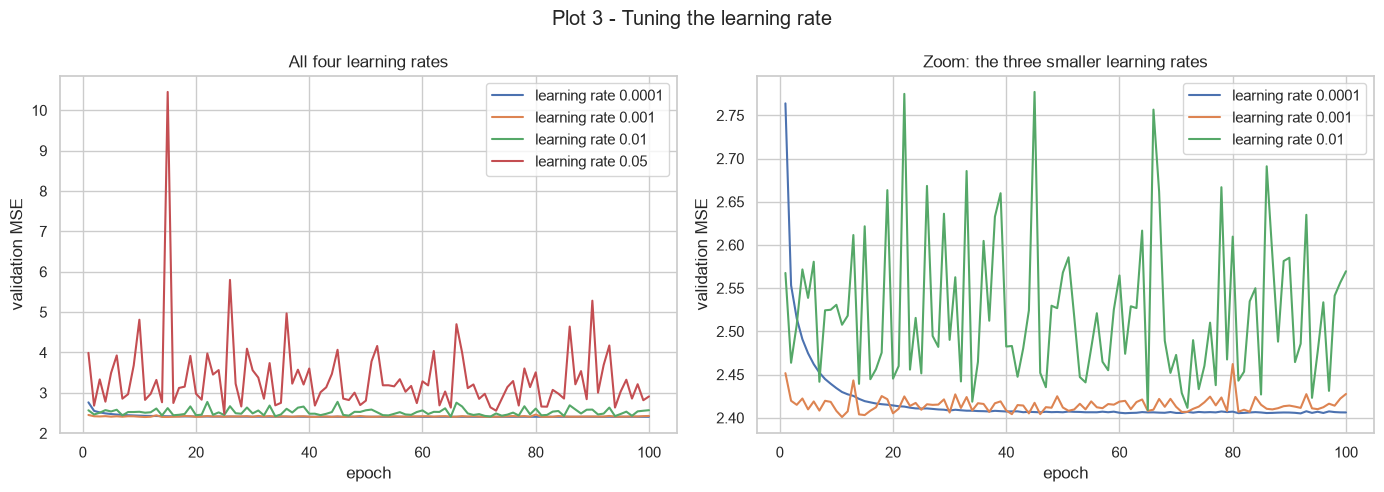

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for lr in LEARNING_RATES:
    axes[0].plot(range(1, 101), val_curves[(lr, BEST_ALPHA)], label=f"learning rate {lr}")
for lr in [0.0001, 0.001, 0.01]:
    axes[1].plot(range(1, 101), val_curves[(lr, BEST_ALPHA)], label=f"learning rate {lr}")
axes[0].set_title("All four learning rates")
axes[1].set_title("Zoom: the three smaller learning rates")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation MSE")
    ax.legend()
fig.suptitle("Plot 3 - Tuning the learning rate")
plt.tight_layout()
plt.show()

what tuning showed 
- the learning rate has the biggest effect 
- alpha changed very little 
- epochs 

Best settings : learning rate 0.0001, alpha 0.001, 100 epochs 

5.2 final gradient descent model and its loss curve 

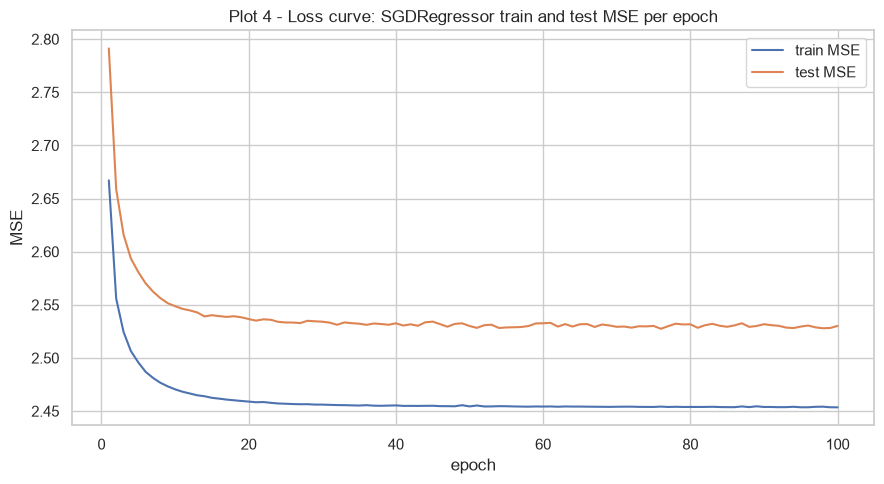

After epoch 1:    train MSE = 2.6671   test MSE = 2.7912
After last epoch: train MSE = 2.4535   test MSE = 2.5301


In [24]:
sgd, sgd_train_curve, sgd_test_curve = train_sgd(
    BEST_LR, BEST_ALPHA, BEST_EPOCHS, X_train_s, y_train.to_numpy(), X_test_s, y_test.to_numpy())

plt.figure(figsize=(9, 5))
plt.plot(range(1, BEST_EPOCHS + 1), sgd_train_curve, label="train MSE")
plt.plot(range(1, BEST_EPOCHS + 1), sgd_test_curve, label="test MSE")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Plot 4 - Loss curve: SGDRegressor train and test MSE per epoch")
plt.legend()
plt.tight_layout()
plt.show()

print("After epoch 1:    train MSE =", round(sgd_train_curve[0], 4), "  test MSE =", round(sgd_test_curve[0], 4))
print("After last epoch: train MSE =", round(sgd_train_curve[-1], 4), "  test MSE =", round(sgd_test_curve[-1], 4))

what the loss curve shows is that both errors fall quickly in the first 10 epochs and then flatten m 

6. Model 2 -  Linear regression , closed form 
this is the same kind of models which uses weighted sum but found in a different way where,  instead of many small steps LinearRegression calculates the weights directly in one step 

In [25]:
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train_s, y_train)

weights = pd.DataFrame({"SGDRegressor": sgd.coef_, "LinearRegression": lin.coef_}, index=feature_names)
weights.round(3)

,SGDRegressor,LinearRegression
rainfall_mm,0.082,0.075
avg_temp_c,-0.305,-0.321
aridity_index,-0.057,-0.062
nitrogen_kg_ha,0.093,0.087
phosphorus_kg_ha,0.117,0.118
country_Burundi,-0.458,-0.797
country_Kenya,0.285,0.003
country_Nigeria,0.241,0.222
country_Rwanda,0.779,0.469
country_Tanzania,0.458,0.180


comparing the two linear models 

7. Model 3 - Decision Tree 
Decision tress asks a serie of yes/no questions . it predicts the average yield of the training fiels that end in the same final group . A tree can learn effects that are not straight lines and features that work together 

In [26]:
from sklearn.tree import DecisionTreeRegressor

depth_rows = []
for depth in [3, 4, 5, 6, 8, 10, 15, None]:
    tree_try = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE)
    tree_try.fit(X_tr_s, y_tr)
    depth_rows.append({"max_depth": str(depth),
                       "train MSE": mean_squared_error(y_tr, tree_try.predict(X_tr_s)),
                       "validation MSE": mean_squared_error(y_val, tree_try.predict(X_val_s))})
depth_table = pd.DataFrame(depth_rows)

best_depth = depth_table.loc[depth_table["validation MSE"].idxmin(), "max_depth"]
BEST_DEPTH = None if best_depth == "None" else int(best_depth)
print("Best max_depth:", BEST_DEPTH)

tree = DecisionTreeRegressor(max_depth=BEST_DEPTH, random_state=RANDOM_STATE)
tree.fit(X_train_s, y_train)
depth_table.round(4)

Best max_depth: 6


,max_depth,train MSE,validation MSE
0,3,2.5084,2.4575
1,4,2.4256,2.3978
2,5,2.3552,2.3993
3,6,2.2675,2.3736
4,8,2.0642,2.4458
5,10,1.7694,2.5482
6,15,0.9452,3.1249
7,None,0.0880,3.9663


what the table shows 

8. Model 4 - Random Forest 

A random forest is an ensemble , it trains many decision trees each on a random sample of rows and average their predictions . one tree can make big mistakes , but the mistakes of many different tress partly cancel out , 

In [27]:
from sklearn.ensemble import RandomForestRegressor

leaf_rows = []
for leaf in [1, 3, 5, 10, 20]:
    forest_try = RandomForestRegressor(n_estimators=150, min_samples_leaf=leaf,
                                       random_state=RANDOM_STATE, n_jobs=-1)
    forest_try.fit(X_tr_s, y_tr)
    leaf_rows.append({"min_samples_leaf": leaf,
                      "train MSE": mean_squared_error(y_tr, forest_try.predict(X_tr_s)),
                      "validation MSE": mean_squared_error(y_val, forest_try.predict(X_val_s))})
leaf_table = pd.DataFrame(leaf_rows)

BEST_LEAF = int(leaf_table.loc[leaf_table["validation MSE"].idxmin(), "min_samples_leaf"])
print("Best min_samples_leaf:", BEST_LEAF)

forest = RandomForestRegressor(n_estimators=150, min_samples_leaf=BEST_LEAF,
                               random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(X_train_s, y_train)
leaf_table.round(4)

Best min_samples_leaf: 10


,min_samples_leaf,train MSE,validation MSE
0,1,0.3691,2.2062
1,3,0.8136,2.1423
2,5,1.1202,2.1116
3,10,1.5078,2.1086
4,20,1.8022,2.1396


what the table shows 

9. Comparing all four models on the same test set 

In [28]:
from sklearn.metrics import r2_score

models = {
    "SGDRegressor (gradient descent)": sgd,
    "LinearRegression (closed form)": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}

rows = []
for name, model in models.items():
    train_mse = mean_squared_error(y_train, model.predict(X_train_s))
    test_mse = mean_squared_error(y_test, model.predict(X_test_s))
    rows.append({"Model": name, "Train MSE": train_mse, "Test MSE": test_mse,
                 "Test RMSE (t/ha)": np.sqrt(test_mse),
                 "Test R2": r2_score(y_test, model.predict(X_test_s))})
comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)

BEST_NAME = comparison.loc[0, "Model"]
best_model = models[BEST_NAME]
print("BEST MODEL (lowest test MSE):", BEST_NAME)

# Reference: a "model" that always predicts the average training yield
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print("Baseline test MSE (always predict the average):", round(baseline_mse, 4))
comparison.round(4)

BEST MODEL (lowest test MSE): RandomForestRegressor
Baseline test MSE (always predict the average): 2.9726


,Model,Train MSE,Test MSE,Test RMSE (t/ha),Test R2
0,RandomForestRegressor,1.4862,2.2178,1.4892,0.2538
1,DecisionTreeRegressor,2.2591,2.4340,1.5601,0.1811
2,LinearRegression (closed form),2.4529,2.5287,1.5902,0.1492
3,SGDRegressor (gradient descent),2.4535,2.5301,1.5906,0.1487


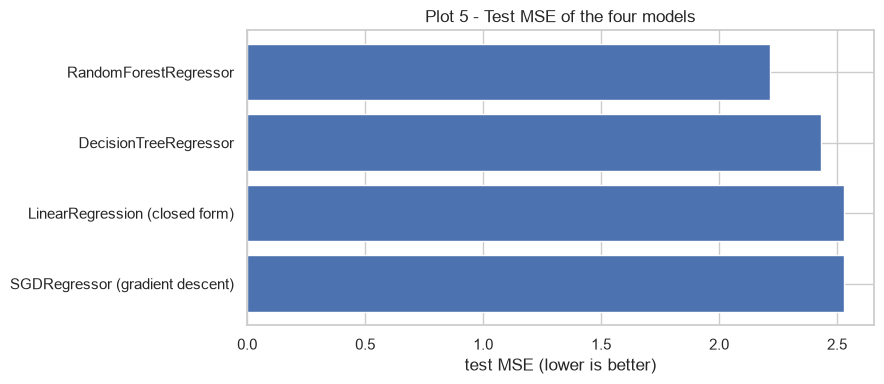

In [29]:
plt.figure(figsize=(9, 4))
plt.barh(comparison["Model"][::-1], comparison["Test MSE"][::-1])
plt.xlabel("test MSE (lower is better)")
plt.title("Plot 5 - Test MSE of the four models")
plt.tight_layout()
plt.show()

Best model : RandomForestRegressor 

10. Scatter plots